# Exploratory Data Analysis

## Overview
This notebook performs Exploratory Data Analysis (EDA) on the processed Indian Agriculture dataset. We explore the distribution of crop yields, missing values, and the impact of geographical and seasonal factors on agricultural output.

In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

## 1. Load Dataset
We begin by loading the cleaned web dataset. This dataset already contains yield, area, and climate features.

In [2]:
df = pd.read_csv('../data/processed/final_data_for_web.csv')
display(df.head())
print(f'Dataset Shape: {df.shape}')

,Unnamed: 0,state_name,district_name,crop_year,season,crop,area,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_mean,latitude,longitude,crop_yield
0,0,andhra pradesh,anantapur,2001,kharif,Arhar/Tur,27942.0,27.047742,1.125806,65.310753,21.16509,14.72422,77.430674,0.272994
1,1,andhra pradesh,anantapur,2001,kharif,Bajra,1595.0,27.047742,1.125806,65.310753,21.16509,14.72422,77.430674,0.329781
2,2,andhra pradesh,anantapur,2001,kharif,Castor seed,3191.0,27.047742,1.125806,65.310753,21.16509,14.72422,77.430674,0.282043
3,3,andhra pradesh,anantapur,2001,kharif,Cotton(lint),8552.0,27.047742,1.125806,65.310753,21.16509,14.72422,77.430674,1.058817
4,4,andhra pradesh,anantapur,2001,kharif,Dry chillies,3765.0,27.047742,1.125806,65.310753,21.16509,14.72422,77.430674,1.892961


Dataset Shape: (249495, 14)


## 2. Missing Values & Data Types
Let's verify the integrity of our dataset.

In [3]:
info_df = pd.DataFrame({'Missing': df.isnull().sum(), 'DType': df.dtypes})
display(info_df[info_df['Missing'] > 0])

,Missing,DType


## 3. Target Distribution (Crop Yield)
Crop yield is heavily right-skewed. Identifying this skew is critical because it justifies our log-transformation later in the pipeline.

In [4]:
fig = px.histogram(df, x='crop_yield', nbins=100, title='Distribution of Crop Yield (tonnes/ha)', marginal='box')
fig.update_layout(xaxis_title='Yield', yaxis_title='Count')
fig.show()

## 4. Categorical Distributions
Let's analyze how many records belong to each state and season.

In [5]:
state_counts = df['state_name'].value_counts().reset_index()
state_counts.columns = ['State', 'Count']
fig = px.bar(state_counts.head(15), x='State', y='Count', title='Top 15 States by Record Count', color='Count')
fig.show()

In [6]:
season_counts = df['season'].value_counts().reset_index()
season_counts.columns = ['Season', 'Count']
fig = px.pie(season_counts, names='Season', values='Count', title='Records by Season')
fig.show()

## 5. Correlation Analysis
Understanding linear correlations between climate features and yield.

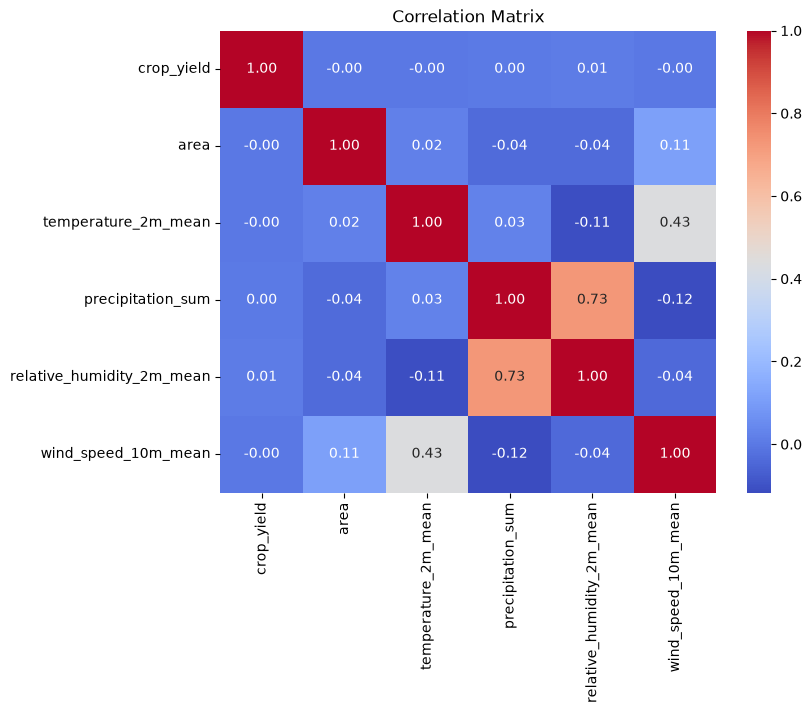

In [7]:
num_cols = ['crop_yield', 'area', 'temperature_2m_mean', 'precipitation_sum', 'relative_humidity_2m_mean', 'wind_speed_10m_mean']
corr = df[num_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()